<a href="https://colab.research.google.com/github/nsgilbert23/Computational-Intelligence-Lab2/blob/main/Lab2_Country_Schools.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2: Country Schools - Anomaly Detection and Cluster Analysis


In [5]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
data = pd.read_csv("Country Schools.csv")
print("data shape:", data.shape)
data.head()

data shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


## 1. Data preprocessing

###  Inspect the raw data

In [8]:
print(data.dtypes)
print("\nMissing values per column:")
print(data.isna().sum())
print("\nLast 4 rows of the raw file:")
data.tail(4)

SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

Missing values per column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Last 4 rows of the raw file:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


#### Interpretation:  data
- The file has **50 rows and 8 columns**, but only **47 are counties**. Row 48 is a `TOTAL` summary row and rows 49-50 are empty (only the `FID` index is filled), which is why every column except `FID` shows exactly 2 missing values.
- The `TOTAL` row must be **removed before analysis**. Left in, it would be the biggest "outlier" in every method (21,729 schools, 723,618 LDDs) and would form its own cluster.
- `PercentageInstalled` was read as text (`10.34%`) and needs converting to a number, and `FID` is only a row index with no information.

### 1.2 Clean the data
Steps: remove the empty rows, remove the `TOTAL` summary row (after using it as a check), tidy county names, convert the percentage text to a number, and test that the numbers are internally consistent.

In [9]:
df = data.copy()

# 1. keep the TOTAL row aside as a control total, then remove blank rows and TOTAL
total_row = df[df["SNO"].astype(str).str.strip().str.upper() == "TOTAL"].iloc[0]
df = df[df["SNO"].notna()]
df = df[df["SNO"].astype(str).str.strip().str.upper() != "TOTAL"].copy()

# 2. tidy names
df["County"] = df["SNO"].str.strip().str.upper().replace({"ELGEYO": "ELGEYO MARAKWET"})

# 3. percentage text -> number
df["PctInstalled"] = df["PercentageInstalled"].str.rstrip("%").astype(float)

# 4. rename columns to short, consistent names
df = df.rename(columns={"TOTALSCHOOLS": "TotalSchools", "TotalSchoolsInstalled": "Installed",
                        "SchoolsPending": "Pending", "InstalledLDDs": "LDDs", "InstalledTDDs": "TDDs"})
df = df[["County", "TotalSchools", "Installed", "Pending", "PctInstalled", "LDDs", "TDDs"]].reset_index(drop=True)
int_cols = ["TotalSchools", "Installed", "Pending", "LDDs", "TDDs"]
df[int_cols] = df[int_cols].astype(int)

print("Clean shape:", df.shape)
print("Duplicate counties:", df["County"].duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))

# 5. consistency checks
print("\nInstalled + Pending == TotalSchools for every county:", bool((df.Installed + df.Pending == df.TotalSchools).all()))
print("Max gap between stated % and recomputed %:", round(float((df.PctInstalled - 100 * df.Installed / df.TotalSchools).abs().max()), 3))
print("TDDs / Installed ratio (min, max):", (df.TDDs / df.Installed).min(), (df.TDDs / df.Installed).max())
print("\nCounty sums vs the file's TOTAL row:")
for c in ["TotalSchools", "Installed", "Pending", "LDDs", "TDDs"]:
    src = {"TotalSchools": "TOTALSCHOOLS", "Installed": "TotalSchoolsInstalled", "Pending": "SchoolsPending",
           "LDDs": "InstalledLDDs", "TDDs": "InstalledTDDs"}[c]
    print(f"  {c:13s} sum={df[c].sum():>8,}   TOTAL row={int(total_row[src]):>8,}")
df.head()

Clean shape: (47, 7)
Duplicate counties: 0
Missing values: 0

Installed + Pending == TotalSchools for every county: True
Max gap between stated % and recomputed %: 0.005
TDDs / Installed ratio (min, max): 2.0 2.0

County sums vs the file's TOTAL row:
  TotalSchools  sum=  21,729   TOTAL row=  21,729
  Installed     sum=  14,629   TOTAL row=  14,629
  Pending       sum=   7,100   TOTAL row=   7,100
  LDDs          sum= 723,618   TOTAL row= 723,618
  TDDs          sum=  29,258   TOTAL row=  29,258


,County,TotalSchools,Installed,Pending,PctInstalled,LDDs,TDDs
0,TURKANA,358,37,321,10.34,3744,74
1,HOMA BAY,875,552,323,63.09,22982,1104
2,WEST POKOT,498,242,256,48.59,15114,484
3,KITUI,1238,1200,38,96.93,42162,2400
4,TANA RIVER,159,143,16,89.94,7415,286


#### Interpretation: cleaning and validation
- After removing the blank and `TOTAL` rows there are **47 counties, no duplicates and no missing values**.
- The county name `ElGEYO ` had stray spacing and mixed case; it was tidied to `ELGEYO MARAKWET`, the full county name (an assumption based on general knowledge, since the file only says "ElGEYO").
- **The data is internally consistent:** `Installed + Pending = TotalSchools` for every county, the stated percentages match the recomputed ones to within 0.005, and the five column sums equal the file's `TOTAL` row exactly (21,729 schools; 14,629 installed; 7,100 pending; 723,618 LDDs; 29,258 TDDs). So any anomaly found later is not a data-entry error in these totals.
- `TDDs` is **always exactly 2 x Installed** (ratio min = max = 2.0), so it carries no extra information and is excluded from the modelling features.

### 1.3 Feature selection and engineering

              count     mean      std    min     25%      50%      75%  \
TotalSchools   47.0    462.3    254.2   93.0   251.5    413.0    633.5   
Installed      47.0    311.3    229.0    8.0   156.5    307.0    408.5   
Pending        47.0    151.1    113.8    4.0    52.5    130.0    243.0   
PctInstalled   47.0     63.9     25.8    4.6    50.3     65.0     84.9   
LDDs           47.0  15396.1  11479.6  606.0  6166.0  13507.0  22838.5   
LDDperSchool   47.0     53.0     19.5   25.7    38.2     47.7     61.5   

                  max  
TotalSchools   1238.0  
Installed      1200.0  
Pending         448.0  
PctInstalled     96.9  
LDDs          44338.0  
LDDperSchool    116.2  

Skewness:
TotalSchools    0.66
Installed       1.43
Pending         0.64
PctInstalled   -0.80
LDDs            0.75
dtype: float64


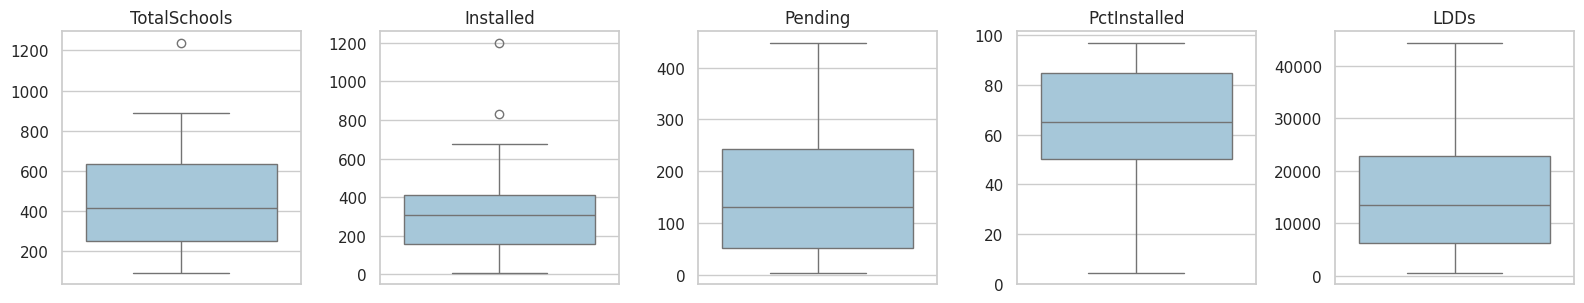

In [10]:
# TDDs is exactly 2 x Installed, so it adds no information -> drop it from modelling.
# Pending = TotalSchools - Installed, but we keep it because it measures the remaining workload.
df["LDDperSchool"] = df["LDDs"] / df["Installed"]          # devices per equipped school (for interpretation)
features = ["TotalSchools", "Installed", "Pending", "PctInstalled", "LDDs"]

print(df[features + ["LDDperSchool"]].describe().round(1).T)
print("\nSkewness:")
print(df[features].skew().round(2))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, c in zip(axes, features):
    sns.boxplot(y=df[c], ax=ax, color="#9ecae1")
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); plt.show()

#### Interpretation: distributions
- The average county has about 462 schools, of which 311 are installed, giving an average coverage of **63.9%** (median 65.0%). Coverage ranges from 4.6% to 96.9%.
- `Installed` is the most right-skewed variable (skewness 1.43): a few counties are far larger than the rest (maximum 1,200 vs median 307). `PctInstalled` is skewed the other way (-0.80): most counties are fairly well covered, with a tail of very low values.
- The boxplots confirm that `TotalSchools` and `Installed` have a clear point above the upper whisker (Kitui), while `PctInstalled` has a long lower tail but no point beyond the whisker.
- The "LDDs per installed school" column has a wide range (25.7 to 116.2), with an average of about 53. It is not used for modelling but shows that device numbers do not scale perfectly with school numbers.

### 1.4 Scaling
Both anomaly detection and clustering are distance-based, so the features are standardized (mean 0, standard deviation 1). Without this, `LDDs` (up to about 44,000) would swamp `PctInstalled` (0 to 100).

Mean after scaling: [-0.0, 0.0, -0.0, 0.0, 0.0]
Std after scaling : [1.0, 1.0, 1.0, 1.0, 1.0]

Correlation matrix of the features:


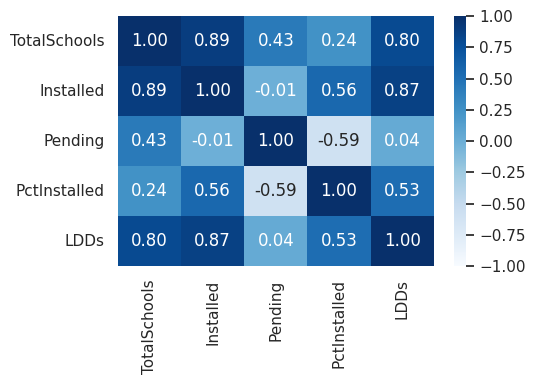

In [11]:
scaler = StandardScaler()
X = scaler.fit_transform(df[features])
Xz = pd.DataFrame(X, columns=features, index=df["County"])
print("Mean after scaling:", Xz.mean().round(6).tolist())
print("Std after scaling :", Xz.std(ddof=0).round(6).tolist())
print("\nCorrelation matrix of the features:")
plt.figure(figsize=(5.5, 4))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.tight_layout(); plt.show()

#### Interpretation: scaling
- After standardizing, every feature has mean 0 and standard deviation 1, so a one-unit difference means "one standard deviation" for every column. Distances in the later steps are therefore not dominated by `LDDs`, which has the largest raw numbers.
- The correlation heatmap shows that `TotalSchools`, `Installed` and `LDDs` are strongly related, as expected, because bigger counties have more schools and more devices. `Installed + Pending = TotalSchools` also means the size columns overlap. The consequence is that **county size carries more weight than coverage** in the distances. This is a limitation to keep in mind when reading the clusters.

## 2. Anomaly detection
Four complementary methods are used, then compared:
- **Z-score** (statistical, one feature at a time)
- **IQR rule** (statistical, one feature at a time, robust to extreme values)
- **Isolation Forest** (model-based, looks at all features together)
- **Local Outlier Factor** (density-based, compares each county with its nearest neighbours)

In [12]:
# 2.1 Z-score
z = Xz.copy()
print("Counties with |z| > 2 on at least one feature:")
flag_z2 = z[(z.abs() > 2).any(axis=1)].round(2)
print(flag_z2)
print("\nCounties with |z| > 2.5:", z.index[(z.abs() > 2.5).any(axis=1)].tolist())
print("Most extreme low value of PctInstalled (z):")
print(z["PctInstalled"].sort_values().head(4).round(2))

Counties with |z| > 2 on at least one feature:
          TotalSchools  Installed  Pending  PctInstalled  LDDs
County                                                        
TURKANA          -0.41      -1.21     1.51         -2.10 -1.03
KITUI             3.08       3.92    -1.00          1.29  2.36
MAKUENI           1.69       2.30    -0.86          1.17  1.37
KAKAMEGA          1.66       1.15     1.39          0.04  2.55
BUNGOMA           1.11       0.64     1.19         -0.09  2.06
MANDERA          -1.05      -1.33     0.34         -2.32 -1.26
WAJIR            -1.00      -1.33     0.43         -2.30 -1.28
MARSABIT         -1.29      -1.34    -0.19         -2.27 -1.30
MACHAKOS          1.49       0.34     2.64         -0.68 -0.18

Counties with |z| > 2.5: ['KITUI', 'KAKAMEGA', 'MACHAKOS']
Most extreme low value of PctInstalled (z):
County
MANDERA    -2.32
WAJIR      -2.30
MARSABIT   -2.27
TURKANA    -2.10
Name: PctInstalled, dtype: float64


#### Interpretation: z-score method
- With a cut-off of |z| > 2.5, only **Kitui, Kakamega and Machakos** are flagged.
  - **Kitui:** very large (z = +3.08 for total schools, +3.92 for installed schools, +2.36 for LDDs).
  - **Kakamega:** very large number of LDDs (+2.55).
  - **Machakos:** very large number of pending schools (+2.64), the highest backlog in the country (448).
- Lowering the cut-off to 2 adds **Makueni, Bungoma and four low-coverage counties (Mandera, Wajir, Marsabit, Turkana)**, whose coverage z-scores are -2.32, -2.30, -2.27 and -2.10.
- These low-coverage counties are not extreme enough to pass the 2.5 cut-off. This shows the limitation of the method: it looks at one feature at a time and uses a hard threshold, and the choice of threshold changes the result.

In [13]:
# 2.2 IQR rule
rows = []
iqr_flags = {}
for c in features:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df.loc[(df[c] < lo) | (df[c] > hi), "County"].tolist()
    rows.append({"feature": c, "lower fence": round(lo, 1), "upper fence": round(hi, 1), "outliers": out})
    for o in out: iqr_flags[o] = iqr_flags.get(o, 0) + 1
pd.DataFrame(rows)

,feature,lower fence,upper fence,outliers
0,TotalSchools,-321.5,1206.5,[KITUI]
1,Installed,-221.5,786.5,"[KITUI, MAKUENI]"
2,Pending,-233.2,528.8,[]
3,PctInstalled,-1.6,136.9,[]
4,LDDs,-18842.8,47847.2,[]


#### Interpretation: IQR rule
- The IQR rule is stricter and flags only **Kitui** (above the upper fence for both `TotalSchools` and `Installed`) and **Makueni** (above the upper fence for `Installed`, 833 vs a fence of 786.5).
- No county is an outlier for `Pending`, `PctInstalled` or `LDDs`. For `PctInstalled` the lower fence is negative (-1.6), so a coverage as low as 4.55% (Mandera) cannot be flagged, because the data are bounded at 0 and 100.
- IQR is robust, since it does not let extreme values distort the thresholds, but it also misses counties that are unusual only in combination (low coverage together with many pending schools).

In [14]:
# 2.3 Isolation Forest (multivariate)
iso = IsolationForest(n_estimators=300, contamination=0.10, random_state=RANDOM_STATE).fit(X)
df["iso_score"] = iso.decision_function(X)          # lower = more anomalous
df["iso_flag"] = iso.predict(X) == -1
print(df.sort_values("iso_score")[["County", "TotalSchools", "PctInstalled", "LDDs", "iso_score", "iso_flag"]].head(8).round(3).to_string(index=False))

  County  TotalSchools  PctInstalled  LDDs  iso_score  iso_flag
   KITUI          1238         96.93 42162     -0.155      True
KAKAMEGA           880         65.00 44338     -0.039      True
 TURKANA           358         10.34  3744     -0.030      True
MACHAKOS           837         46.48 13369     -0.025      True
 MAKUENI           887         93.91 30973     -0.017      True
    LAMU            93         95.70  3083      0.011     False
 BUNGOMA           741         61.54 38744      0.013     False
MARSABIT           138          5.80   606      0.014     False


#### Interpretation: Isolation Forest
- Isolation Forest looks at all five features at once and isolates unusual combinations with few random splits. A **lower score means more anomalous**.
- It flags 5 counties (10% contamination, an assumption): **Kitui (-0.155), Kakamega (-0.039), Turkana (-0.030), Machakos (-0.025) and Makueni (-0.017)**.
- Kitui is by far the most isolated, with a score about four times lower than the next county.
- **Turkana** is flagged only by this method. It is unusual because of its combination of a mid-size school base (358) with very low coverage (10.34%), not because any single value is extreme. This is the type of anomaly that the one-feature methods missed.

In [15]:
# 2.4 Local Outlier Factor (density-based)
lof = LocalOutlierFactor(n_neighbors=5, contamination=0.10)
df["lof_flag"] = lof.fit_predict(X) == -1
df["lof_score"] = -lof.negative_outlier_factor_      # ~1 = normal, >1.5 = suspicious
print(df.sort_values("lof_score", ascending=False)[["County", "lof_score", "lof_flag"]].head(8).round(2).to_string(index=False))

  County  lof_score  lof_flag
   KITUI       2.35      True
KAKAMEGA       1.57      True
 MAKUENI       1.48      True
 BUNGOMA       1.29      True
 SAMBURU       1.23      True
MACHAKOS       1.18     False
   NANDI       1.17     False
 TURKANA       1.13     False


#### Interpretation: Local Outlier Factor
- LOF compares the density around each county with the density around its 5 nearest neighbours. A score near 1 is normal; higher values mean a county is more isolated than its neighbours.
- The top flags are **Kitui (2.35), Kakamega (1.57), Makueni (1.48), Bungoma (1.29) and Samburu (1.23)**. Only Kitui has a score clearly above 2; the others are mild.
- LOF does **not** flag Turkana (1.13) or Mandera, Wajir and Marsabit. These low-coverage counties sit close together, so each has similar neighbours. They are a **small group with a shared unusual pattern** rather than isolated points, which a neighbour-based method treats as normal.
- Samburu is flagged because of local sparsity, not because it is extreme. It should be treated as weak evidence.

  County  Z>2.5   IQR  IsolationForest   LOF  votes
   KITUI   True  True             True  True      4
 MAKUENI  False  True             True  True      3
KAKAMEGA   True False             True  True      3
MACHAKOS   True False             True False      2
 TURKANA  False False             True False      1
 BUNGOMA  False False            False  True      1
 SAMBURU  False False            False  True      1


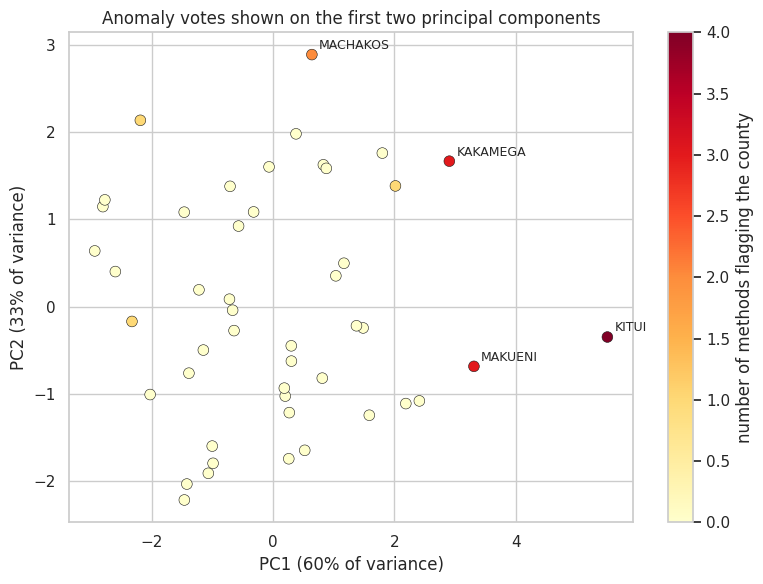

In [16]:
# 2.5 Compare the methods
summary = pd.DataFrame({"County": df["County"]})
summary["Z>2.5"] = (z.abs() > 2.5).any(axis=1).values
summary["IQR"] = summary["County"].map(lambda c: c in iqr_flags)
summary["IsolationForest"] = df["iso_flag"].values
summary["LOF"] = df["lof_flag"].values
summary["votes"] = summary[["Z>2.5", "IQR", "IsolationForest", "LOF"]].sum(axis=1)
flagged = summary[summary.votes > 0].sort_values("votes", ascending=False)
print(flagged.to_string(index=False))

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
plt.figure(figsize=(8, 6))
plt.scatter(P[:, 0], P[:, 1], c=summary["votes"], cmap="YlOrRd", s=60, edgecolor="k", linewidth=0.4)
for i in summary.index[summary.votes >= 2]:
    plt.annotate(df.County[i], (P[i, 0], P[i, 1]), xytext=(5, 4), textcoords="offset points", fontsize=9)
plt.colorbar(label="number of methods flagging the county")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("Anomaly votes shown on the first two principal components")
plt.tight_layout(); plt.show()

#### Interpretation: comparing the four methods
| County | Methods flagging | Why |
|---|---|---|
| **Kitui** | 4 of 4 | Largest county (1,238 schools) with the highest installed count (1,200) and 96.9% coverage |
| **Makueni** | 3 of 4 | Very large installed base (833) and 93.9% coverage |
| **Kakamega** | 3 of 4 | Highest LDD count (44,338) combined with a large pending backlog (308) |
| **Machakos** | 2 of 4 | Largest pending backlog (448 schools) |
| Turkana, Bungoma, Samburu | 1 of 4 | Weak evidence, detected by one method only |

- **Kitui** is the strongest anomaly: all four methods agree, and it is visibly separated from the rest on the PCA plot (PC1 and PC2 explain 60% and 33% of the variance).
- Agreement between methods is a better guide than any single method. Counties flagged by 3-4 methods deserve attention; counties flagged by one method are borderline.
- **These anomalies are not errors.** The data checks above showed the numbers are consistent, so these are genuine extreme cases. Kitui, Makueni and Kakamega are unusual because they are very large, while Machakos is unusual for its backlog.
- Anomaly detection says *which* counties differ, not *why*. The reason has to come from field knowledge.

## 3. Cluster analysis
Goal: group counties with a similar school-installation profile. Three algorithms are used: **K-Means**, **hierarchical (Ward)** and **DBSCAN**.

 k  inertia  silhouette
 2    143.8       0.343
 3    102.7       0.322
 4     71.5       0.392
 5     55.3       0.371
 6     42.9       0.385
 7     35.1       0.382
 8     28.4       0.388


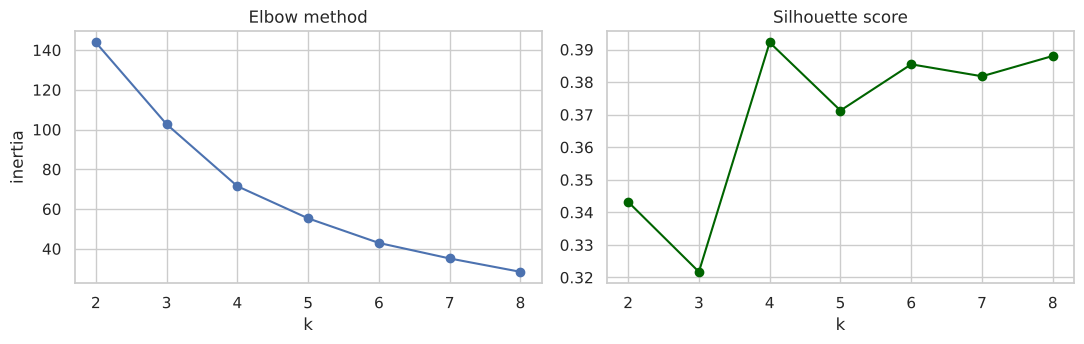

In [ ]:
# 3.1 Choose k for K-Means (elbow + silhouette)
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
res = pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(list(ks), sil, "o-", color="darkgreen"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

#### Interpretation: choosing the number of clusters
- The elbow curve falls steadily with no sharp bend, so the elbow method alone is not decisive.
- The silhouette score is highest at **k = 4 (0.392)**, higher than for k = 2 (0.343), k = 3 (0.322) and k = 5 (0.371). k = 6 to 8 are close (0.382-0.388) but give smaller, harder-to-use groups.
- **k = 4** is chosen: it has the best silhouette and gives groups that are easy to describe.
- A silhouette of about 0.39 means a **moderate** structure: the groups are real but overlap. The counties form more of a continuum than clear-cut islands.

In [17]:
# 3.2 K-Means with k = 4
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
df["kmeans"] = km.labels_
print("Silhouette score:", round(silhouette_score(X, km.labels_), 3))

# order clusters by average % installed so the labels are easy to read
order = df.groupby("kmeans")["PctInstalled"].mean().sort_values(ascending=False).index.tolist()
rename = {old: new for new, old in enumerate(order)}
df["kmeans"] = df["kmeans"].map(rename)

profile = df.groupby("kmeans")[["TotalSchools", "Installed", "Pending", "PctInstalled", "LDDs"]].mean().round(1)
profile["counties"] = df.groupby("kmeans").size()
print(profile)
for c in range(K):
    print(f"\nCluster {c}:", ", ".join(df.loc[df.kmeans == c, "County"]))

Silhouette score: 0.392
        TotalSchools  Installed  Pending  PctInstalled     LDDs  counties
kmeans                                                                   
0              743.1      675.6     67.6          89.8  30577.1         7
1              306.2      231.6     74.6          76.6  11254.1        20
2              676.7      382.7    294.0          55.9  20761.1        13
3              229.4       41.7    187.7          16.6   2086.0         7

Cluster 0: KITUI, NAROK, NANDI, MAKUENI, KISUMU, BOMET, KILIFI

Cluster 1: TANA RIVER, TAITA TAVETA, UASIN GISHU, VIHIGA, NYAMIRA, MOMBASA, LAMU, BUSIA, ELGEYO MARAKWET, TRANS NZOIA, KWALE, LAIKIPIA, KIRINYAGA, ISIOLO, MURANG'A, NYANDARUA, NAIROBI, THARAKA NITHI, KAJIADO, EMBU

Cluster 2: HOMA BAY, WEST POKOT, MIGORI, KISII, KAKAMEGA, BUNGOMA, SIAYA, KERICHO, MERU, KIAMBU, MACHAKOS, NAKURU, BARINGO

Cluster 3: TURKANA, GARISSA, MANDERA, NYERI, WAJIR, MARSABIT, SAMBURU


#### Interpretation: K-Means (k = 4)
| Cluster | Counties | Avg schools | Avg coverage | Avg pending | Profile |
|---|---|---|---|---|---|
| **0** | 7 | 743 | 89.8% | 68 | **Large and almost complete.** Kitui, Narok, Nandi, Makueni, Kisumu, Bomet, Kilifi |
| **1** | 20 | 306 | 76.6% | 75 | **Small to medium and mostly done.** The largest group, including Nairobi, Mombasa, Kajiado, Embu, Lamu |
| **2** | 13 | 677 | 55.9% | 294 | **Large with a big backlog.** Homa Bay, Migori, Kisii, Kakamega, Bungoma, Siaya, Kericho, Meru, Machakos, Nakuru, Baringo, West Pokot, Kiambu |
| **3** | 7 | 229 | 16.6% | 188 | **Lagging.** Turkana, Garissa, Mandera, Wajir, Marsabit, Samburu, Nyeri |

- The clusters mainly separate on **coverage and county size**. Cluster 3 has only about 42 installed schools per county on average, against 676 in cluster 0.
- **Priority for action:** cluster 3 has the lowest coverage but few schools, so catching up is cheap per county, while cluster 2 has the largest backlog (294 pending schools per county on average, about 3,800 in total) and needs the most resources.
- The five lowest-coverage counties (Mandera 4.55%, Wajir 5.21%, Marsabit 5.80%, Turkana 10.34%, Garissa 19.02%) are all in cluster 3. They are mostly northern, arid counties (general knowledge, not in the data). **Nyeri** is the odd one out in this cluster: it has 37.5% coverage and 245 pending schools, so it is more of a mid-coverage county than a remote one.
- The silhouette of 0.392 means some counties sit near a cluster boundary, so the groups are a useful summary rather than a hard classification.

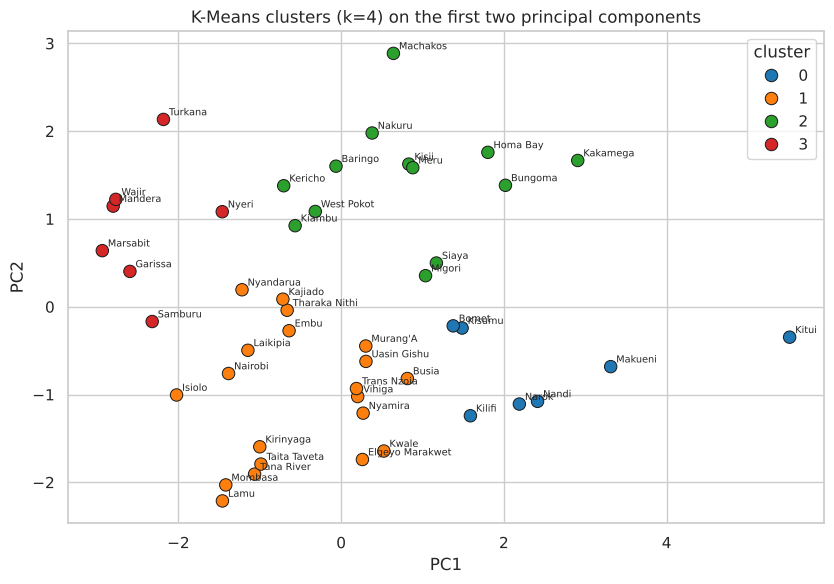

PCA loadings:
               PC1   PC2
TotalSchools  0.51  0.34
Installed     0.56  0.00
Pending       0.01  0.76
PctInstalled  0.36 -0.55
LDDs          0.54  0.02


In [ ]:
# 3.3 Visualize K-Means clusters on two principal components
plt.figure(figsize=(8.5, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["kmeans"], palette="tab10", s=80, edgecolor="k")
for i in range(len(df)):
    plt.annotate(df.County[i].title(), (P[i, 0], P[i, 1]), xytext=(4, 3), textcoords="offset points", fontsize=7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("K-Means clusters (k=4) on the first two principal components")
plt.legend(title="cluster"); plt.tight_layout(); plt.show()

print("PCA loadings:")
print(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2))

#### Interpretation: cluster map and loadings
- **PC1** (60% of variance) is a **size and installation** axis: `Installed`, `LDDs`, `TotalSchools` and `PctInstalled` all load positively (0.54-0.56, 0.51 and 0.36). Counties on the right have many schools and devices.
- **PC2** (33% of variance) is a **backlog** axis: `Pending` loads +0.76 and `PctInstalled` loads -0.55, so high values mean many pending schools and low coverage.
- Cluster 3 sits at the bottom left (small, behind), cluster 0 at the right (large, done), cluster 2 at the top (large backlog) and cluster 1 in the middle-left (small, mostly complete). The two components together explain 93% of the variance, so the 2-D picture is a reliable summary.

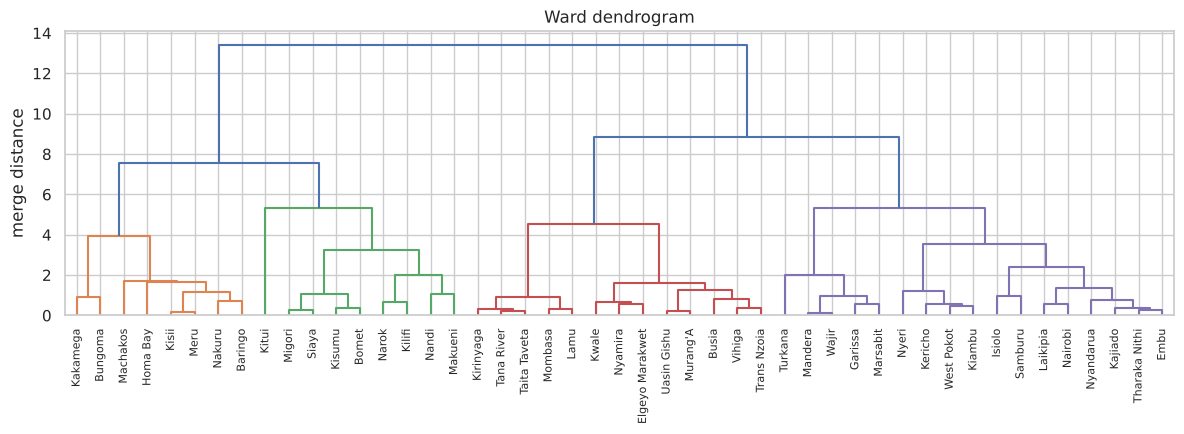

Ward silhouette (k=4): 0.325
Agreement with K-Means (adjusted Rand index): 0.435
ward    0  1   2  3
kmeans             
0       0  7   0  0
1       0  0  13  7
2       8  2   0  3
3       0  0   0  7


In [ ]:
# 3.4 Hierarchical clustering (Ward linkage)
Z = linkage(X, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, labels=df["County"].str.title().values, leaf_rotation=90, leaf_font_size=8, color_threshold=Z[-3, 2])
plt.title("Ward dendrogram"); plt.ylabel("merge distance"); plt.tight_layout(); plt.show()

df["ward"] = fcluster(Z, t=K, criterion="maxclust") - 1
print("Ward silhouette (k=4):", round(silhouette_score(X, df["ward"]), 3))
print("Agreement with K-Means (adjusted Rand index):", round(adjusted_rand_score(df["kmeans"], df["ward"]), 3))
print(pd.crosstab(df["kmeans"], df["ward"], rownames=["kmeans"], colnames=["ward"]))

#### Interpretation: hierarchical clustering
- The dendrogram shows a first split between **15 large counties** (left side: Kakamega, Bungoma, Machakos, Homa Bay, Kitui, Narok, Makueni and others) and **32 smaller counties** (right side).
- Kitui and Turkana show up as long single branches that join their groups late, which agrees with the anomaly results.
- With 4 clusters, Ward has a silhouette of 0.325, lower than K-Means (0.392), and the **adjusted Rand index between the two methods is only 0.435**. They agree on the main structure (large complete counties, a coherent lagging group), but disagree on the boundary counties. For example, 7 of K-Means' 20 cluster-1 counties go to a different Ward cluster.
- When two algorithms give moderately different answers, the cluster edges are not stable. Counties near a boundary should not be over-interpreted.

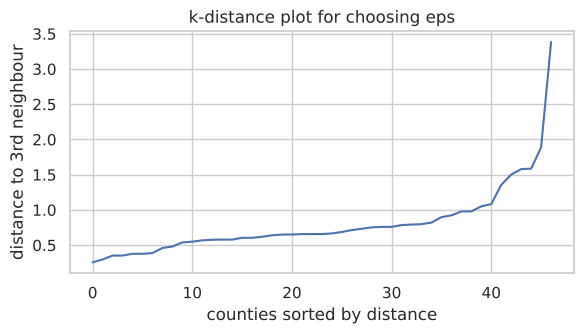

eps=0.8: clusters=7, noise points=8
eps=1.0: clusters=3, noise points=6
eps=1.2: clusters=1, noise points=4
eps=1.5: clusters=1, noise points=3

Chosen eps=1.0
Noise (6): Turkana, Kitui, Makueni, Kakamega, Bungoma, Machakos
Cluster 0 (32): Homa Bay, West Pokot, Uasin Gishu, Vihiga, Nyamira, Narok, Nandi, Kisii, Kilifi, Busia, Elgeyo Marakwet, Trans Nzoia, Kwale, Kericho, Meru, Garissa, Laikipia, Mandera, Isiolo, Kiambu, Murang'A, Nyeri, Wajir, Nyandarua, Marsabit, Nairobi, Nakuru, Tharaka Nithi, Baringo, Kajiado, Embu, Samburu
Cluster 1 (5): Tana River, Taita Taveta, Mombasa, Lamu, Kirinyaga
Cluster 2 (4): Migori, Kisumu, Bomet, Siaya


In [ ]:
# 3.5 DBSCAN (density-based, also finds noise)
nn = NearestNeighbors(n_neighbors=3).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])
plt.figure(figsize=(6, 3.5)); plt.plot(kdist); plt.xlabel("counties sorted by distance"); plt.ylabel("distance to 3rd neighbour")
plt.title("k-distance plot for choosing eps"); plt.tight_layout(); plt.show()

for eps in (0.8, 1.0, 1.2, 1.5):
    lab = DBSCAN(eps=eps, min_samples=3).fit_predict(X)
    print(f"eps={eps}: clusters={len(set(lab)) - (1 if -1 in lab else 0)}, noise points={(lab == -1).sum()}")

db = DBSCAN(eps=1.0, min_samples=3).fit(X)
df["dbscan"] = db.labels_
print("\nChosen eps=1.0")
for lab, g in df.groupby("dbscan"):
    print(("Noise" if lab == -1 else f"Cluster {lab}") + f" ({len(g)}):", ", ".join(g["County"].str.title()))

#### Interpretation: DBSCAN
- The sweep over `eps` suggests `eps = 1.0` as a reasonable middle value (3 clusters, 6 noise points). With a smaller eps (0.8) there are 7 clusters and 8 noise points; with a larger eps (1.2 and above) almost everything merges into one cluster.
- With `eps = 1.0`, DBSCAN produces **one large dense group (32 counties)**, two small groups (Tana River, Taita Taveta, Mombasa, Lamu, Kirinyaga; and Migori, Kisumu, Bomet, Siaya) and **6 noise counties: Turkana, Kitui, Makueni, Kakamega, Bungoma and Machakos**.
- The noise list is almost the same as the anomaly list (it contains all four counties flagged by at least two methods), which is a good independent confirmation. It also includes Turkana and Bungoma.
- The weakness is that DBSCAN puts the low-coverage counties (Mandera, Wajir, Marsabit) together with most others because they are not far apart in five-dimensional space. It is good for detecting outliers but less useful than K-Means for building a meaningful grouping of this data set. It is also sensitive to `eps`, so the result should be reported with the chosen value.

In [ ]:
# 3.6 Anomalies vs clusters: are the flagged counties in small or unusual clusters?
out = summary.merge(df[["County", "kmeans", "dbscan"]], on="County")
print(out[out.votes >= 2].to_string(index=False))
print("\nDBSCAN noise counties:", df.loc[df.dbscan == -1, "County"].str.title().tolist())

  County  Z>2.5   IQR  IsolationForest   LOF  votes  kmeans  dbscan
   KITUI   True  True             True  True      4       0      -1
 MAKUENI  False  True             True  True      3       0      -1
KAKAMEGA   True False             True  True      3       2      -1
MACHAKOS   True False             True False      2       2      -1

DBSCAN noise counties: ['Turkana', 'Kitui', 'Makueni', 'Kakamega', 'Bungoma', 'Machakos']


#### Interpretation: anomalies and clusters together
- All four counties flagged by two or more methods are also **DBSCAN noise**, and they are the large, high-activity counties: Kitui and Makueni (K-Means cluster 0) and Kakamega and Machakos (cluster 2).
- The anomalies are therefore **extreme members of the large-county clusters**, not a separate type of county. The low-coverage counties (cluster 3) are a distinct group rather than outliers.
- This is a useful distinction: anomaly detection finds *individual* unusual cases (Kitui), while clustering finds *groups* with a shared pattern (the lagging counties).

## 4. Overall conclusions

### Preprocessing
- 50 raw rows became **47 counties** after removing the `TOTAL` row and two empty rows. Names and the percentage column were cleaned, and the totals reconcile exactly with the file's own `TOTAL` row.
- `TDDs` was dropped (always 2 x installed schools). The five remaining numeric features were standardized.

### Anomaly detection
- **Kitui** is the clear anomaly (4 of 4 methods). **Makueni** and **Kakamega** follow (3 of 4), then **Machakos** (2 of 4). They are real extreme values, not errors.
- Different methods catch different things: z-score and IQR find single extreme values, Isolation Forest finds unusual combinations (Turkana), and LOF finds local sparsity. Using several methods and counting agreement is more reliable than using one.

### Cluster analysis
- K-Means with k = 4 gives interpretable groups: **large and nearly complete (7), small and mostly done (20), large with a big backlog (13), lagging (7)**.
- The structure is **moderate** (silhouette 0.39), and Ward only partly agrees with K-Means (ARI 0.435), so boundary counties should be treated with care.

### Limitations
- Only 47 observations, and a single snapshot in time.
- The size columns overlap, so size has more influence than coverage in the distances.
- The 10% contamination used in Isolation Forest and LOF, `eps` for DBSCAN and k for K-Means are choices, and results change with them.
- The reasons for the patterns (for example, why some northern counties are lagging) are not in the data and need outside information.